# Proyecto 2 - Visión artificial
## Clasificación binaria de radiografías de tórax con PneumoniaMNIST

**Integrantes**
- Angel David Avirama de Oro
- Leonardo Guevara Atehortua

**Base de datos:** [PneumoniaMNIST — TensorFlow Datasets](https://www.tensorflow.org/datasets/catalog/pneumonia_mnist)

### Objetivo
Desarrollar y comparar modelos de clasificación de imágenes mediante transferencia de aprendizaje y fine tuning con las arquitecturas VGG16 y ResNet50, para clasificar radiografías de tórax en dos categorías: normal y neumonía.

**Alcance:** trabajo académico de experimentación en visión artificial. Los resultados no constituyen una herramienta de diagnóstico médico ni sustituyen la evaluación de profesionales de salud.

## 1. Descripción del problema y del conjunto de datos

PneumoniaMNIST es un conjunto de imágenes de radiografías de tórax adaptado para investigación en aprendizaje automático. Las imágenes están reducidas a **28 × 28 píxeles** y son en escala de grises. El problema se plantea como **clasificación binaria supervisada**.

- **Dominio:** análisis de imágenes médicas.
- **Entrada:** una imagen de radiografía de tórax.
- **Variable de salida (`label`):** categoría asignada a la imagen: normal o neumonía.
- **Clases:** 0 = normal y 1 = neumonía (se comprobará la codificación al cargar el dataset).
- **Utilidad potencial:** estudiar cómo las redes convolucionales aprenden patrones visuales en imágenes médicas.
- **Limitación:** la resolución reducida elimina detalles; el conjunto de datos y el modelo no son aptos para uso clínico.

Se usarán las particiones oficiales de entrenamiento, validación y prueba proporcionadas por el dataset. La partición de prueba se reservará para la evaluación final, no para ajustar hiperparámetros.


## 2. Instalación e importación de bibliotecas

El conjunto de datos se carga directamente desde TensorFlow Datasets

In [ ]:
%pip install -q importlib-resources

In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import tensorflow_datasets as tfds

from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("TensorFlow Datasets:", tfds.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
TensorFlow Datasets: 4.9.10
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Carga del conjunto de datos

El conjunto se carga directamente desde TensorFlow Datasets mediante `tfds.load`. La opción `as_supervised=True` entrega cada ejemplo como un par formado por imagen y etiqueta, mientras que `with_info=True` permite consultar la descripción y el número de ejemplos de cada partición.

Se utilizan las particiones oficiales de entrenamiento, validación y prueba. La partición de prueba se reserva para la evaluación final.

In [ ]:
DATASET_NAME = "pneumonia_mnist"

(train_raw, val_raw, test_raw), info = tfds.load(
    DATASET_NAME,
    split=["train", "val", "test"],
    as_supervised=True,
    with_info=True,
    shuffle_files=False
)

print(info)
print("\nNúmero de ejemplos por partición:")
print("Entrenamiento:", info.splits["train"].num_examples)
print("Validación:", info.splits["val"].num_examples)
print("Prueba:", info.splits["test"].num_examples)


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/3 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/pneumonia_mnist/incomplete.HBRPOI_1.0.0/pneumonia_mnist-train.tfrecord-[0-…

Generating val examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/pneumonia_mnist/incomplete.HBRPOI_1.0.0/pneumonia_mnist-val.tfrecord-[0-9]…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/pneumonia_mnist/incomplete.HBRPOI_1.0.0/pneumonia_mnist-test.tfrecord-[0-9…

Dataset pneumonia_mnist downloaded and prepared to /root/tensorflow_datasets/pneumonia_mnist/1.0.0. Subsequent calls will reuse this data.
tfds.core.DatasetInfo(
    name='pneumonia_mnist',
    full_name='pneumonia_mnist/1.0.0',
    description="""
    # MedMNIST Pneumonia Dataset
    
    The PneumoniaMNIST is based on a prior dataset of 5,856 pediatric chest X-Ray
    images. The task is binary-class classification of pneumonia against normal. The
    source training set is split with a ratio of 9:1 into training and validation
    set, and use its source validation set as the test set. The source images are
    gray-scale, and their sizes are (384–2,916) × (127–2,713). The images are
    center-cropped with a window size of length of the short edge and resized into 1
    × 28 × 28.
    """,
    homepage='https://medmnist.com//',
    data_dir='/root/tensorflow_datasets/pneumonia_mnist/1.0.0',
    file_format=tfrecord,
    download_size=3.98 MiB,
    dataset_size=3.66 MiB,
    feature

## 4. Análisis exploratorio de datos

Se inspeccionan las dimensiones y el tipo de datos de las imágenes, se visualizan ejemplos de las dos clases y se compara la distribución de etiquetas en las particiones de entrenamiento, validación y prueba.

In [ ]:
for image, label in train_raw.take(1):
    print("Forma de imagen:", image.shape)
    print("Tipo de dato:", image.dtype)
    print("Etiqueta original:", label.numpy())
    print("Rango de píxeles:", tf.reduce_min(image).numpy(), "a", tf.reduce_max(image).numpy())


Forma de imagen: (28, 28, 1)
Tipo de dato: <dtype: 'uint8'>
Etiqueta original: 0
Rango de píxeles: 50 a 233


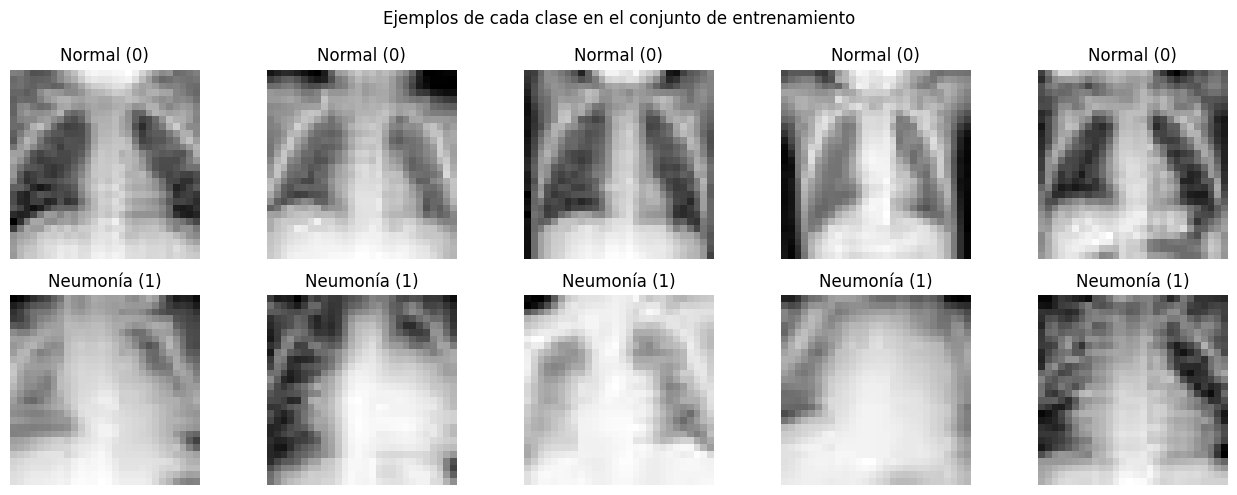

In [ ]:
class_names = ["Normal (0)", "Neumonía (1)"]

examples = {0: [], 1: []}
for image, label in train_raw:
    y = int(tf.reshape(label, []).numpy())
    if y in examples and len(examples[y]) < 5:
        examples[y].append(image.numpy())
    if all(len(examples[k]) >= 5 for k in examples):
        break

fig, axes = plt.subplots(2, 5, figsize=(13, 5))
for row, cls in enumerate([0, 1]):
    for col in range(5):
        ax = axes[row, col]
        if col < len(examples[cls]):
            img = np.squeeze(examples[cls][col])
            ax.imshow(img, cmap="gray")
            ax.set_title(class_names[cls])
        ax.axis("off")
plt.suptitle("Ejemplos de cada clase en el conjunto de entrenamiento")
plt.tight_layout()
plt.show()


,Normal (0),Neumonía (1)
Entrenamiento,1214,3494
Validación,135,389
Prueba,234,390


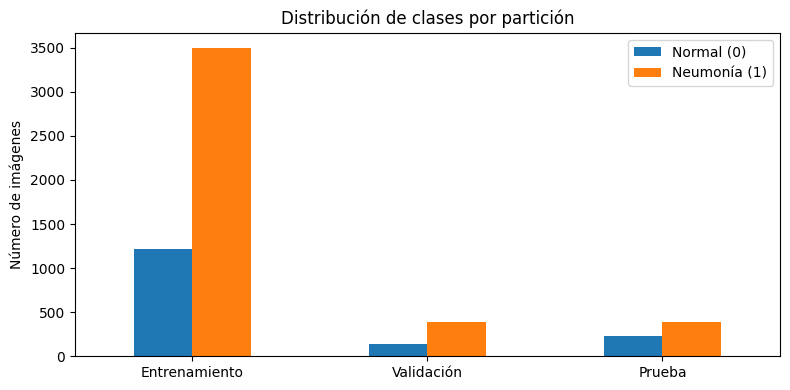

In [ ]:
# Distribución de clases por partición
def count_labels(ds):
    counts = {0: 0, 1: 0}
    for _, label in ds:
        y = int(tf.reshape(label, []).numpy())
        counts[y] = counts.get(y, 0) + 1
    return counts

counts_by_split = {
    "Entrenamiento": count_labels(train_raw),
    "Validación": count_labels(val_raw),
    "Prueba": count_labels(test_raw),
}
counts_df = pd.DataFrame(counts_by_split).T.rename(
    columns={0: "Normal (0)", 1: "Neumonía (1)"}
)
display(counts_df)

counts_df.plot(kind="bar", figsize=(8, 4))
plt.title("Distribución de clases por partición")
plt.ylabel("Número de imágenes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Resolución de las imágenes

PneumoniaMNIST contiene imágenes de 28 × 28 píxeles en escala de grises. Al ampliarlas para mostrarlas, los píxeles se hacen visibles. El redimensionamiento a 96 × 96 permite utilizar las arquitecturas elegidas, pero no recupera detalles que no están presentes en la imagen original.

## 5. Preprocesamiento

VGG16 y ResNet50 fueron preentrenadas con imágenes RGB de mayor tamaño. Para adaptar PneumoniaMNIST se realizan los siguientes pasos:

1. Convertir las imágenes a tipo `float32`.
2. Replicar el canal de escala de grises para obtener tres canales.
3. Redimensionar las imágenes a 96 × 96 píxeles.
4. Aplicar la función de preprocesamiento correspondiente a cada arquitectura.
5. Convertir las etiquetas a valores numéricos compatibles con la clasificación binaria.

El redimensionamiento permite adaptar las entradas al modelo, pero no añade información nueva a las imágenes.

In [ ]:
IMG_SIZE = (96, 96)
AUTOTUNE = tf.data.AUTOTUNE

def prepare_image(image, label):
    image = tf.cast(image, tf.float32)
    # Asegurar forma (alto, ancho, canales)
    if image.shape.rank == 2:
        image = image[..., tf.newaxis]
    image = tf.image.grayscale_to_rgb(image)
    image = tf.image.resize(image, IMG_SIZE)
    # Mantener valores en [0, 255] para preprocess_input de Keras
    image = tf.clip_by_value(image, 0.0, 255.0)
    label = tf.cast(tf.reshape(label, []), tf.float32)
    return image, label

def make_dataset(raw_ds, training=False, batch_size=32):
    ds = raw_ds.map(prepare_image, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.shuffle(1024, seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(batch_size).prefetch(AUTOTUNE)
    return ds


## 6. Transferencia de aprendizaje y fine tuning

Se comparan dos arquitecturas preentrenadas con ImageNet:

- **VGG16:** red convolucional organizada en bloques secuenciales, útil como arquitectura clásica de referencia.
- **ResNet50:** red residual que incorpora conexiones de salto para facilitar el entrenamiento de redes profundas.

Para cada arquitectura se utiliza una cabeza clasificadora nueva. Primero se congela la base preentrenada y se entrena la cabeza; después se descongelan las últimas capas de la base y se continúa el entrenamiento con una tasa de aprendizaje menor. Esta segunda etapa corresponde al fine tuning.

La salida es una neurona con activación `sigmoid`, adecuada para la clasificación binaria, y se utiliza la función de pérdida `binary_crossentropy`.

In [ ]:
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import VGG16, ResNet50
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess

def build_model(architecture="VGG16", dropout=0.3, unfreeze_last=4):
    inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3), name="image")

    # Aumento de datos solo durante entrenamiento
    x = layers.RandomFlip("horizontal")(inputs)
    x = layers.RandomRotation(0.05)(x)
    x = layers.RandomZoom(0.1)(x)

    if architecture.upper() == "VGG16":
        x = layers.Lambda(vgg_preprocess, name="vgg_preprocess")(x)
        base = VGG16(
            include_top=False, weights="imagenet",
            input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)
        )
    elif architecture.upper() == "RESNET50":
        x = layers.Lambda(resnet_preprocess, name="resnet_preprocess")(x)
        base = ResNet50(
            include_top=False, weights="imagenet",
            input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)
        )
    else:
        raise ValueError("Arquitectura no reconocida")

    # Fase 1: congelar todas las capas de la base
    base.trainable = False
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(1, activation="sigmoid", name="prob_neumonia")(x)
    model = Model(inputs, outputs, name=f"{architecture}_transfer")
    return model, base


### ¿Cómo se organizan las épocas?

El entrenamiento se divide en dos fases. Primero se entrena la cabeza clasificadora nueva mientras la base preentrenada permanece congelada; después se ajustan las últimas cuatro capas de la base mediante *fine tuning*.

La búsqueda compara estos pares de máximos de épocas:

| Épocas de la cabeza (`epochs_head`) | Épocas de fine tuning (`epochs_fine`) |
|---:|---:|
| 5 | 2 |
| 10 | 3 |
| 20 | 5 |
| 30 | 10 |

En todas las configuraciones, el máximo de épocas de *fine tuning* es menor que el de la cabeza clasificadora. Una época corresponde a una pasada por los datos de entrenamiento. `EarlyStopping`, con `monitor="val_loss"` y `patience=3`, puede detener cada fase antes de alcanzar el máximo y restaurar los pesos de la mejor época de esa fase.

Separar las dos fases permite adaptar primero el clasificador y después ajustar ligeramente parte de la red preentrenada. El número de épocas no determina por sí solo la calidad: las configuraciones se comparan mediante las métricas de validación y el conjunto de prueba se reserva para la evaluación final.

## Justificación de las arquitecturas

Se eligieron VGG16 y ResNet50 para comparar dos diseños de redes convolucionales con características diferentes.

| Criterio | VGG16 | ResNet50 |
|---|---|---|
| Diseño | Bloques secuenciales de convoluciones 3 × 3 | Bloques residuales con conexiones de salto |
| Profundidad | 16 capas con pesos | 50 capas con pesos |
| Ventaja | Arquitectura clásica y sencilla de interpretar | Las conexiones residuales facilitan el flujo del gradiente en redes profundas |
| Parámetros de la base sin la cabeza clasificadora | Aproximadamente 14,7 millones | Aproximadamente 23,6 millones |
| Uso en el experimento | Referencia de transferencia de aprendizaje | Comparación con una arquitectura residual más profunda |

ResNet50 se utiliza en lugar de ResNet18 porque está disponible directamente en Keras Applications junto con VGG16. ResNet18 es una alternativa más pequeña, pero normalmente requiere otra implementación o biblioteca.

La cantidad de parámetros ofrece una referencia del tamaño del modelo, aunque el tiempo de ejecución también depende de la resolución, el tamaño del lote, el hardware y las operaciones de cada arquitectura. No se presupone que una arquitectura sea mejor por ser más profunda: la selección se basa en las métricas obtenidas sobre el conjunto de validación.

En el notebook de clase se presenta un flujo similar de transferencia de aprendizaje y se utiliza EfficientNetV2L como modelo principal, con ResNet50 y VGG19 como alternativas. En este proyecto se emplean VGG16 y ResNet50 para cumplir el requisito de comparar al menos dos arquitecturas y analizar sus resultados con el mismo conjunto de datos.

## Búsqueda de hiperparámetros: épocas, tasa de aprendizaje y tamaño de lote

Se comparan dos arquitecturas (VGG16 y ResNet50), dos tasas de aprendizaje, cuatro configuraciones de épocas y tres tamaños de lote. En cada configuración, el número máximo de épocas de *fine tuning* es menor que el de la cabeza clasificadora:

| Épocas de la cabeza (`epochs_head`) | Épocas de fine tuning (`epochs_fine`) |
|---:|---:|
| 5 | 2 |
| 10 | 3 |
| 20 | 5 |
| 30 | 10 |

Se probarán los tamaños de lote **16, 32 y 64**. Un lote pequeño actualiza los pesos usando menos imágenes por paso; uno mayor procesa más imágenes antes de cada actualización y puede requerir más memoria.

La malla contiene hasta **48 experimentos** (2 arquitecturas × 2 tasas de aprendizaje × 4 configuraciones de épocas × 3 tamaños de lote). `EarlyStopping` puede terminar cada fase antes del máximo establecido si la pérdida de validación deja de mejorar. Por ello, el número indicado es un límite, no una garantía de que se ejecuten todas las épocas.

La selección del mejor experimento se hace con la pérdida de validación (`val_loss`). El tamaño de lote correspondiente al experimento ganador también se utilizará al evaluar el conjunto de prueba. La partición de prueba se reserva para la evaluación final, no para ajustar hiperparámetros. Esta malla puede tardar bastante; se recomienda ejecutar el notebook en Colab con GPU y guardar una copia antes de comenzar.

In [ ]:
# Configuración de los experimentos
EPOCH_CONFIGS = [
    (5, 2),
    (10, 3),
    (20, 5),
    (30, 10)
]
LEARNING_RATES = [1e-3, 1e-4]
BATCH_SIZES = [16, 32, 64]
ARCHITECTURES = ["VGG16", "ResNet50"]

# Cada tupla representa (épocas de la cabeza, épocas de fine tuning).
# En todas las configuraciones, epochs_fine es menor que epochs_head.
results = []
trained_models = {}
histories = {}

for architecture in ARCHITECTURES:
    for lr in LEARNING_RATES:
        for batch_size in BATCH_SIZES:
            for epochs_head, epochs_fine in EPOCH_CONFIGS:
                print(
                    f"\nArquitectura={architecture} | learning_rate={lr} | "
                    f"batch_size={batch_size} | epochs_head={epochs_head} | "
                    f"epochs_fine={epochs_fine}"
                )
                tf.keras.backend.clear_session()

                train_ds = make_dataset(
                    train_raw, training=True, batch_size=batch_size
                )
                val_ds = make_dataset(
                    val_raw, training=False, batch_size=batch_size
                )

                model, base = build_model(architecture, dropout=0.3)
                model.compile(
                    optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                    loss="binary_crossentropy",
                    metrics=[
                        "accuracy",
                        tf.keras.metrics.Precision(name="precision"),
                        tf.keras.metrics.Recall(name="recall"),
                        tf.keras.metrics.AUC(name="auc")
                    ]
                )

                callbacks_head = [
                    tf.keras.callbacks.EarlyStopping(
                        monitor="val_loss",
                        patience=3,
                        restore_best_weights=True,
                        verbose=1
                    )
                ]

                # Fase 1: entrenar la cabeza clasificadora con la base congelada.
                history = model.fit(
                    train_ds,
                    validation_data=val_ds,
                    epochs=epochs_head,
                    callbacks=callbacks_head,
                    verbose=1
                )

                # Fase 2: fine tuning de las últimas cuatro capas de la base.
                base.trainable = True
                for layer in base.layers[:-4]:
                    layer.trainable = False

                # Las capas BatchNormalization permanecen congeladas.
                for layer in base.layers:
                    if isinstance(layer, tf.keras.layers.BatchNormalization):
                        layer.trainable = False

                model.compile(
                    optimizer=tf.keras.optimizers.Adam(learning_rate=lr / 10),
                    loss="binary_crossentropy",
                    metrics=[
                        "accuracy",
                        tf.keras.metrics.Precision(name="precision"),
                        tf.keras.metrics.Recall(name="recall"),
                        tf.keras.metrics.AUC(name="auc")
                    ]
                )

                callbacks_fine = [
                    tf.keras.callbacks.EarlyStopping(
                        monitor="val_loss",
                        patience=2,
                        restore_best_weights=True,
                        verbose=1
                    )
                ]
                history_fine = model.fit(
                    train_ds,
                    validation_data=val_ds,
                    epochs=epochs_fine,
                    callbacks=callbacks_fine,
                    verbose=1
                )

                val_metrics = model.evaluate(
                    val_ds, return_dict=True, verbose=0
                )
                key = (
                    f"{architecture}_lr{lr}_batch{batch_size}_"
                    f"head{epochs_head}_fine{epochs_fine}"
                )
                trained_models[key] = model
                histories[key] = (history, history_fine)

                results.append({
                    "experimento": key,
                    "arquitectura": architecture,
                    "learning_rate_inicial": lr,
                    "batch_size": batch_size,
                    "epochs_head_max": epochs_head,
                    "epochs_fine_max": epochs_fine,
                    **{f"val_{k}": v for k, v in val_metrics.items()}
                })

results_df = pd.DataFrame(results).sort_values("val_loss").reset_index(drop=True)
display(results_df)
print(f"Total de configuraciones evaluadas: {len(results_df)}")


Arquitectura=VGG16 | learning_rate=0.001 | batch_size=16 | epochs_head=5 | epochs_fine=2
Epoch 1/5
295/295 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - accuracy: 0.8895 - auc: 0.9318 - loss: 0.3281 - precision: 0.9244 - recall: 0.9270 - val_accuracy: 0.9198 - val_auc: 0.9729 - val_loss: 0.1974 - val_precision: 0.9578 - val_recall: 0.9332
Epoch 2/5
295/295 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.9282 - auc: 0.9708 - loss: 0.1881 - precision: 0.9493 - recall: 0.9542 - val_accuracy: 0.9427 - val_auc: 0.9796 - val_loss: 0.1543 - val_precision: 0.9544 - val_recall: 0.9692
Epoch 3/5
295/295 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.9286 - auc: 0.9750 - loss: 0.1759 - precision: 0.9501 - recall: 0.9539 - val_accuracy: 0.9198 - val_auc: 0.9832 - val_loss: 0.1897 - val_precision: 0.9780 - val_recall: 0.9126
Epoch 4/5
295/295 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.9386 - auc: 0.9782 - loss: 0.1613 - precision: 0.9569 - recall: 0.9605 - val_accuracy: 0.9027 - val_auc: 0.9824 - val

,experimento,arquitectura,learning_rate_inicial,batch_size,epochs_head_max,epochs_fine_max,val_accuracy,val_auc,val_loss,val_precision,val_recall
0,VGG16_lr0.001_batch64_head20_fine5,VGG16,0.0010,64,20,5,0.980916,0.995297,0.069355,0.987147,0.987147
1,VGG16_lr0.001_batch16_head30_fine10,VGG16,0.0010,16,30,10,0.971374,0.996173,0.069948,0.977041,0.984576
2,VGG16_lr0.001_batch16_head20_fine5,VGG16,0.0010,16,20,5,0.973282,0.995820,0.070103,0.984496,0.979434
3,VGG16_lr0.001_batch64_head30_fine10,VGG16,0.0010,64,30,10,0.973282,0.995915,0.071633,0.977099,0.987147
4,VGG16_lr0.001_batch64_head5_fine2,VGG16,0.0010,64,5,2,0.971374,0.995706,0.073251,0.984456,0.976864
5,VGG16_lr0.001_batch32_head30_fine10,VGG16,0.0010,32,30,10,0.967557,0.995144,0.077280,0.981865,0.974293
6,VGG16_lr0.001_batch64_head10_fine3,VGG16,0.0010,64,10,3,0.971374,0.995230,0.077794,0.977041,0.984576
7,VGG16_lr0.0001_batch32_head30_fine10,VGG16,0.0001,32,30,10,0.969466,0.995373,0.080755,0.981912,0.976864
8,VGG16_lr0.001_batch16_head5_fine2,VGG16,0.0010,16,5,2,0.967557,0.995297,0.089306,0.989474,0.966581
9,VGG16_lr0.001_batch32_head10_fine3,VGG16,0.0010,32,10,3,0.963740,0.994278,0.090040,0.979275,0.971722


Total de configuraciones evaluadas: 48


## 8. Selección del mejor modelo

Se selecciona el experimento con la menor pérdida de validación (`val_loss`). También se consideran la exactitud, la precisión, el recall y el AUC para interpretar el comportamiento del clasificador. El conjunto de prueba se utiliza únicamente para la evaluación final.

In [ ]:
best_row = results_df.iloc[0]
best_key = best_row["experimento"]
best_model = trained_models[best_key]
best_batch_size = int(best_row["batch_size"])
print("Mejor experimento según val_loss:", best_key)
print("Tamaño de lote del mejor experimento:", best_batch_size)
print(best_row)

Mejor experimento según val_loss: VGG16_lr0.001_batch64_head20_fine5
Tamaño de lote del mejor experimento: 64
experimento              VGG16_lr0.001_batch64_head20_fine5
arquitectura                                          VGG16
learning_rate_inicial                                 0.001
batch_size                                               64
epochs_head_max                                          20
epochs_fine_max                                           5
val_accuracy                                       0.980916
val_auc                                            0.995297
val_loss                                           0.069355
val_precision                                      0.987147
val_recall                                         0.987147
Name: 0, dtype: object


## 9. Curvas de entrenamiento

Las curvas permiten identificar si el modelo aprende, si se estanca o si hay señales de sobreajuste. Se grafican por separado las fases de entrenamiento de la cabeza clasificadora y de fine tuning.


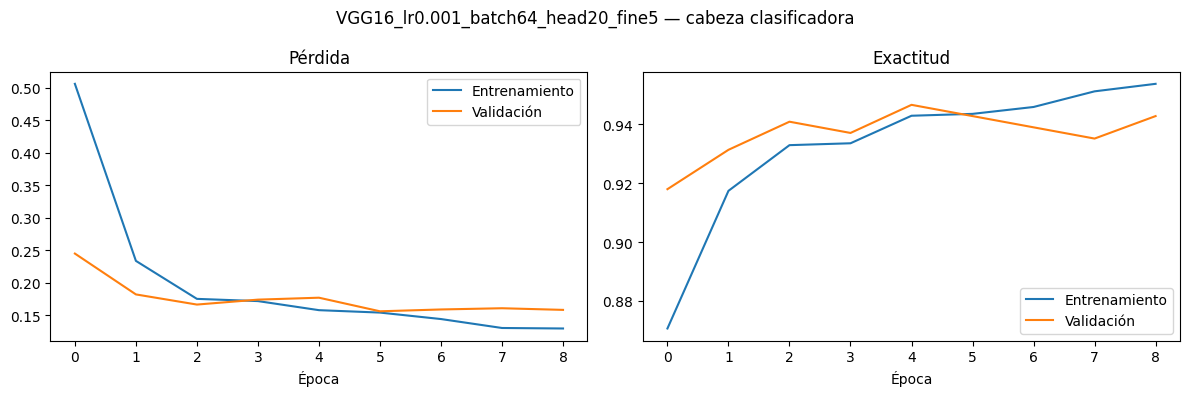

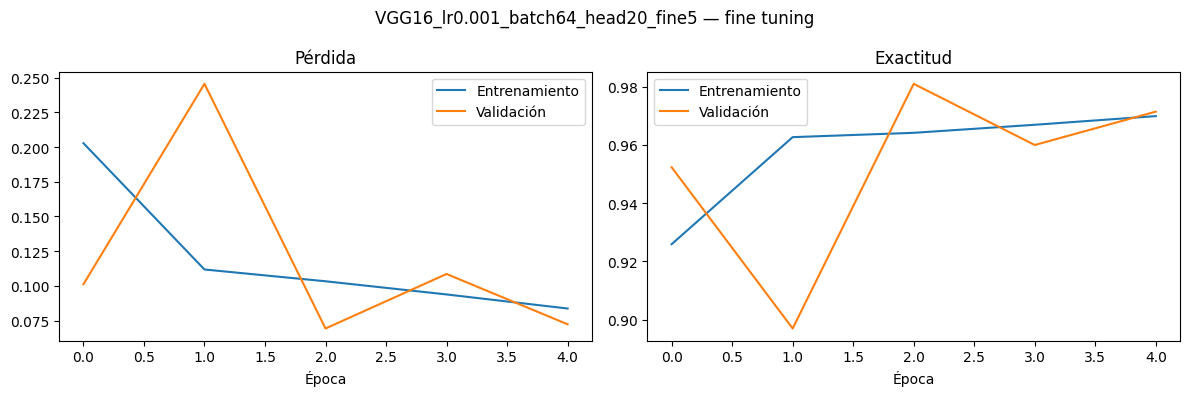

In [ ]:
head_history, fine_history = histories[best_key]

def plot_history(history, title):
    hist = pd.DataFrame(history.history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(hist["loss"], label="Entrenamiento")
    axes[0].plot(hist["val_loss"], label="Validación")
    axes[0].set_title("Pérdida")
    axes[0].set_xlabel("Época")
    axes[0].legend()
    axes[1].plot(hist["accuracy"], label="Entrenamiento")
    axes[1].plot(hist["val_accuracy"], label="Validación")
    axes[1].set_title("Exactitud")
    axes[1].set_xlabel("Época")
    axes[1].legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_history(head_history, f"{best_key} — cabeza clasificadora")
plot_history(fine_history, f"{best_key} — fine tuning")


## 10. Evaluación final en el conjunto de prueba

El modelo seleccionado se evalúa sobre la partición de prueba. Se reportan la pérdida, la exactitud, la precisión, el recall, el AUC, el reporte por clase y la matriz de confusión.

El recall de la clase Neumonía indica la proporción de imágenes etiquetadas como neumonía que el modelo clasificó correctamente. Las métricas se interpretan dentro del alcance académico del proyecto; no validan el uso clínico del sistema.

10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 102ms/step - accuracy: 0.8958 - auc: 0.9605 - loss: 0.3899 - precision: 0.8652 - recall: 0.9872
Métricas en prueba:
accuracy: 0.8958
auc: 0.9605
loss: 0.3899
precision: 0.8652
recall: 0.9872
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 84ms/step

Reporte de clasificación:
              precision    recall  f1-score   support

      Normal       0.97      0.74      0.84       234
    Neumonía       0.87      0.99      0.92       390

    accuracy                           0.90       624
   macro avg       0.92      0.87      0.88       624
weighted avg       0.91      0.90      0.89       624



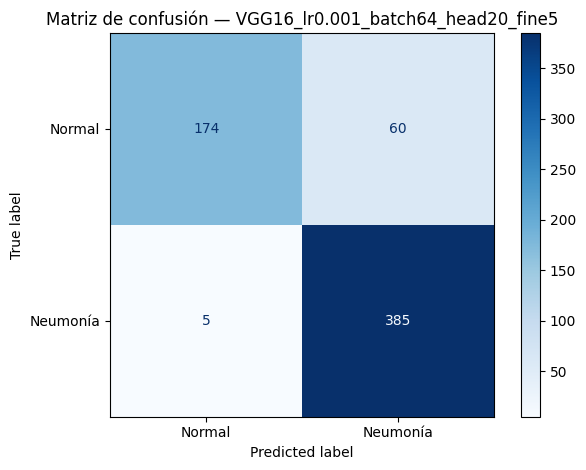

ROC-AUC: 0.9701


In [ ]:
test_ds = make_dataset(test_raw, training=False, batch_size=best_batch_size)
test_metrics = best_model.evaluate(test_ds, return_dict=True, verbose=1)
print("Métricas en prueba:")
for metric, value in test_metrics.items():
    print(f"{metric}: {value:.4f}")

y_true = np.concatenate([
    np.asarray(labels).reshape(-1)
    for _, labels in test_ds
]).astype(int)

y_prob = best_model.predict(test_ds, verbose=1).reshape(-1)
y_pred = (y_prob >= 0.5).astype(int)

print("\nReporte de clasificación:")
print(classification_report(
    y_true, y_pred,
    labels=[0, 1],
    target_names=["Normal", "Neumonía"],
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Neumonía"]
)
disp.plot(values_format="d", cmap="Blues")
plt.title(f"Matriz de confusión — {best_key}")
plt.tight_layout()
plt.show()

if len(np.unique(y_true)) == 2:
    print("ROC-AUC:", round(roc_auc_score(y_true, y_prob), 4))


## 11. Conclusiones

En este proyecto se desarrolló un experimento de clasificación binaria de radiografías de tórax de PneumoniaMNIST mediante transferencia de aprendizaje y *fine tuning*. Se compararon VGG16 y ResNet50, dos tasas de aprendizaje iniciales (0,001 y 0,0001), cuatro pares de máximos de épocas para la cabeza clasificadora y el fine tuning, y tres tamaños de lote (16, 32 y 64). Se ejecutaron 48 configuraciones y cada fase podía detenerse antes mediante `EarlyStopping`.

### Mejor configuración según validación

La configuración seleccionada automáticamente por presentar la menor pérdida de validación fue VGG16, learning rate inicial 0,001, batch size 64, máximo de 20 épocas para la cabeza y 5 para fine tuning. Obtuvo `val_loss = 0,0694`, `val_accuracy = 98,09 %` y `val_auc = 99,53 %`. La selección se realizó con la pérdida de validación, no con los resultados del conjunto de prueba.

Al comparar promedios de las 48 configuraciones, VGG16 tuvo mejores resultados de validación que ResNet50 en esta experimentación: su pérdida media de validación fue aproximadamente 0,1037 frente a 0,1577, y su exactitud media fue 96,13 % frente a 94,09 %. Esto no demuestra que VGG16 sea siempre superior; la conclusión se limita a este conjunto de datos y a las configuraciones evaluadas.

El learning rate inicial de 0,001 obtuvo mejores promedios que 0,0001 en la malla ejecutada. Los tamaños de lote tuvieron promedios relativamente cercanos: 32 presentó la menor pérdida media de validación (0,1278), mientras que el ganador individual utilizó batch size 64. Por tanto, el tamaño de lote con mejor promedio no fue el mismo que el de la mejor configuración individual. En cuanto a las épocas, los pares con máximos más altos (20/5 y 30/10) mostraron, en promedio, una pérdida de validación algo menor que los pares 5/2 y 10/3; `EarlyStopping` hizo que los máximos no necesariamente fueran las épocas efectivamente completadas.

### Evaluación final en el conjunto de prueba

El modelo seleccionado obtuvo 89,58 % de exactitud, pérdida de prueba de 0,3899, precisión de 86,52 % y recall de 98,72 % para la clase positiva (Neumonía), según las métricas calculadas por Keras. El cálculo ROC-AUC con `sklearn` sobre las probabilidades predichas fue 0,9701.

La matriz de confusión registró 174 imágenes normales correctamente clasificadas como normales, 60 imágenes normales clasificadas erróneamente como neumonía, 5 imágenes con neumonía clasificadas erróneamente como normales y 385 imágenes con neumonía correctamente identificadas. El recall de Neumonía fue alto (98,72 %), lo que significa que el modelo identificó la mayoría de los casos positivos del conjunto de prueba. Sin embargo, el recall para la clase Normal fue de aproximadamente 74 %, por lo que hubo una cantidad considerable de falsos positivos: 60 imágenes normales fueron clasificadas como neumonía. La exactitud de validación (98,09 %) fue superior a la exactitud de prueba (89,58 %), lo que evidencia una diferencia de rendimiento entre ambas particiones y aconseja cautela al generalizar los resultados.

### Limitaciones y trabajo futuro

Las imágenes originales tienen una resolución de solo 28 × 28 píxeles. Redimensionarlas a 96 × 96 permite adaptarlas a las arquitecturas preentrenadas, pero no recupera los detalles que no existen en los datos originales. Además, la distribución de clases no es uniforme, por lo que conviene considerar el desempeño por clase y no únicamente la exactitud global. Como mejoras futuras se podría estudiar el ajuste del umbral de clasificación usando exclusivamente validación, ampliar la evaluación con otras particiones o conjuntos externos y comparar arquitecturas adicionales.

En conclusión, VGG16 con learning rate inicial de 0,001, batch size 64 y máximos de 20/5 épocas fue la mejor configuración de las evaluadas según `val_loss`. La evaluación final mostró un buen recall para Neumonía, pero también errores al clasificar imágenes normales. Este trabajo es académico y experimental; los resultados no constituyen validación clínica ni deben utilizarse para diagnosticar pacientes.